# Punto 5 – Construcción de mapas de temperatura
**Trabajo 1 de Hidroclimatología · Cuenca del río Cauca hasta Hidroituango**

Con las relaciones del punto 4 y el DEM de la cuenca se construyen, por **álgebra de mapas**, los campos de
Tmax, Tmin y Tmed. A cada celda se le aplica

$$T(y) = T_0 - \alpha\,Z(y)$$

donde $Z(y)$ es la elevación de la celda. Los mapas quedan limitados a la cuenca porque el DEM ya está recortado.

Después se analiza:
- el efecto de la elevación sobre la temperatura,
- los sectores más fríos y más cálidos,
- la coherencia espacial de los resultados.

**Archivos en la misma carpeta de este notebook:**
- `DEM_cuenca.tif` (punto 2)
- `cuenca_cauca.gpkg` (punto 2)
- `parametros_T.json` y `estaciones_T_seleccionadas.csv` (punto 4)
- `rio_principal.gpkg` (punto 2, opcional, solo para el dibujo)

**Salidas:** `Tmax.tif`, `Tmin.tif`, `Tmed.tif` (°C) y `pisos_termicos.tif`. El notebook del punto 6 los usa.

## 0. Instalación de librerías
Solo si no las instaló antes. Después de instalar, reinicie el kernel.

In [1]:
%pip install numpy pandas matplotlib geopandas rasterio

Note: you may need to restart the kernel to use updated packages.


## 1. Librerías y parámetros
Los parámetros $T_0$ y $\alpha$ se leen de `parametros_T.json`, generado en el punto 4. Si no tiene ese archivo,
escríbalos a mano en `PARAMETROS_MANUALES`.

In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource, ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import geopandas as gpd
import rasterio

pd.set_option("display.width", 200)

# ----------------------------- PARÁMETROS -----------------------------
DEM = "DEM_cuenca.tif"
CUENCA = "cuenca_cauca.gpkg"
RIO = "rio_principal.gpkg"                    # opcional
PARAMETROS_JSON = "parametros_T.json"         # salida del punto 4
ESTACIONES_T = "estaciones_T_seleccionadas.csv"
CRS = "EPSG:3116"
NODATA = -9999.0
PARAMETROS_MANUALES = None   # p.ej. {"tmax": {"T0": 36.31, "alpha_C_por_m": 0.00714}, "tmin": {...}, "tmed": {...}}
# ----------------------------------------------------------------------

if PARAMETROS_MANUALES is None:
    with open(PARAMETROS_JSON, encoding="utf-8") as f:
        PAR = json.load(f)
else:
    PAR = PARAMETROS_MANUALES

NOMBRES = {"tmax": "Temperatura máxima media", "tmin": "Temperatura mínima media", "tmed": "Temperatura media"}
for v in ("tmax", "tmin", "tmed"):
    p = PAR[v]
    print(f"{NOMBRES[v]:26s}  T = {p['T0']:.2f} − {p['alpha_C_por_m']:.5f}·Z   (α = {p['alpha_C_por_m']*1000:.2f} °C/km)")

Temperatura máxima media    T = 36.33 − 0.00711·Z   (α = 7.11 °C/km)
Temperatura mínima media    T = 24.30 − 0.00574·Z   (α = 5.74 °C/km)
Temperatura media           T = 29.99 − 0.00640·Z   (α = 6.40 °C/km)


## 2. Lectura del DEM de la cuenca

Celdas en la cuenca: 40,633  | tamaño de celda: 932 m  | área: 35,283 km²
Elevación: mínima 322 m, media 1795 m, máxima 5141 m


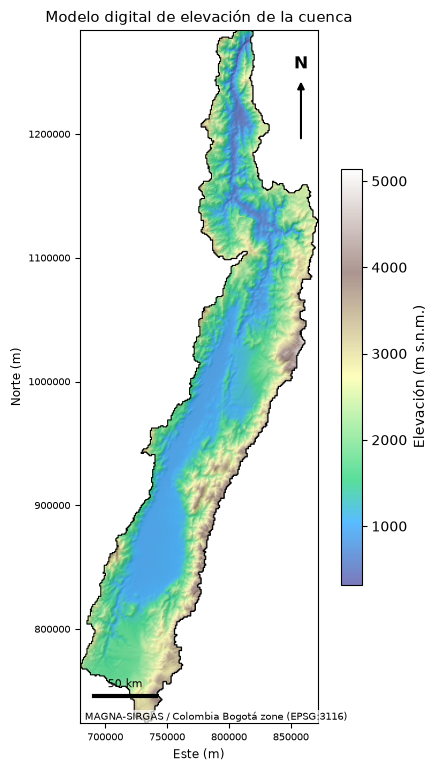

In [3]:
with rasterio.open(DEM) as src:
    Z = src.read(1, masked=True).astype("float64")
    perfil = src.profile.copy()
    T = src.transform

celda_km2 = abs(T.a * T.e) / 1e6
ext = [T.c, T.c + T.a * Z.shape[1], T.f + T.e * Z.shape[0], T.f]   # extensión para imshow
cuenca = gpd.read_file(CUENCA).to_crs(CRS)
rio = gpd.read_file(RIO).to_crs(CRS) if os.path.exists(RIO) else None

print(f"Celdas en la cuenca: {Z.count():,}  | tamaño de celda: {T.a:.0f} m  | área: {Z.count() * celda_km2:,.0f} km²")
print(f"Elevación: mínima {Z.min():.0f} m, media {Z.mean():.0f} m, máxima {Z.max():.0f} m")

# Sombreado del relieve para dar contexto a los mapas
Zf = Z.filled(float(Z.mean()))
sombra = np.ma.masked_array(LightSource(azdeg=315, altdeg=45).hillshade(Zf, vert_exag=3, dx=T.a, dy=abs(T.e)),
                            mask=np.ma.getmaskarray(Z))


def decorar(ax, titulo):
    # límite de cuenca, río, flecha de norte, barra de escala y SRC
    cuenca.boundary.plot(ax=ax, color="k", lw=0.8)
    if rio is not None:
        rio.plot(ax=ax, color="#08306b", lw=1.0)
    ax.annotate("", xy=(0.93, 0.93), xytext=(0.93, 0.84), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
    ax.text(0.93, 0.945, "N", transform=ax.transAxes, ha="center", fontsize=12, fontweight="bold")
    x0 = ext[0] + 0.06 * (ext[1] - ext[0]); y0 = ext[2] + 0.04 * (ext[3] - ext[2])
    ax.plot([x0, x0 + 50000], [y0, y0], "k-", lw=3)
    ax.text(x0 + 25000, y0 + 0.012 * (ext[3] - ext[2]), "50 km", ha="center", fontsize=8)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)")
    ax.text(0.02, 0.005, "MAGNA-SIRGAS / Colombia Bogotá zone (EPSG:3116)", transform=ax.transAxes, fontsize=7,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))
    ax.ticklabel_format(style="plain"); ax.tick_params(labelsize=7)
    ax.locator_params(axis="x", nbins=4)
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(6, 9))
ax.imshow(sombra, extent=ext, cmap="gray")
im = ax.imshow(Z, extent=ext, cmap="terrain", alpha=0.65)
plt.colorbar(im, ax=ax, shrink=0.6, label="Elevación (m s.n.m.)")
decorar(ax, "Modelo digital de elevación de la cuenca")
plt.show()

## 3. Álgebra de mapas: T = T₀ − αZ
Se aplica la ecuación de cada variable a todas las celdas del DEM.

In [4]:
mapas = {v: PAR[v]["T0"] - PAR[v]["alpha_C_por_m"] * Z for v in ("tmax", "tmin", "tmed")}

perfil.update(dtype="float32", nodata=NODATA, count=1, compress="lzw", crs=CRS)
for v, archivo in (("tmax", "Tmax.tif"), ("tmin", "Tmin.tif"), ("tmed", "Tmed.tif")):
    with rasterio.open(archivo, "w", **perfil) as dst:
        dst.write(mapas[v].filled(NODATA).astype("float32"), 1)

resumen = pd.DataFrame({NOMBRES[v]: {"mínima (°C)": m.min(), "media (°C)": m.mean(), "máxima (°C)": m.max(),
                                     "desv. estándar (°C)": m.std()} for v, m in mapas.items()}).T
print("Guardados: Tmax.tif, Tmin.tif, Tmed.tif")
resumen.round(2)

Guardados: Tmax.tif, Tmin.tif, Tmed.tif


,mínima (°C),media (°C),máxima (°C),desv. estándar (°C)
Temperatura máxima media,-0.24,23.56,34.04,5.63
Temperatura mínima media,-5.19,14.00,22.45,4.54
Temperatura media,-2.89,18.51,27.93,5.06


## 4. Mapas de temperatura
Primero, cada variable con su propia escala de color. Después, las tres con la **misma escala**, para comparar
magnitudes directamente.

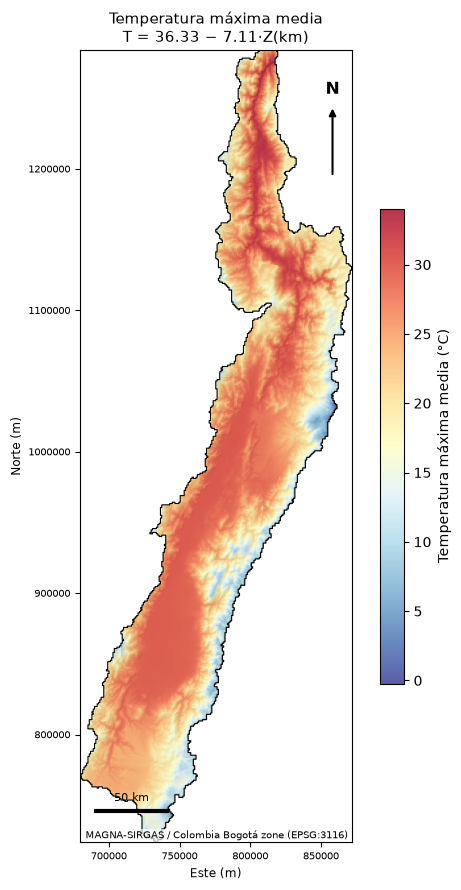

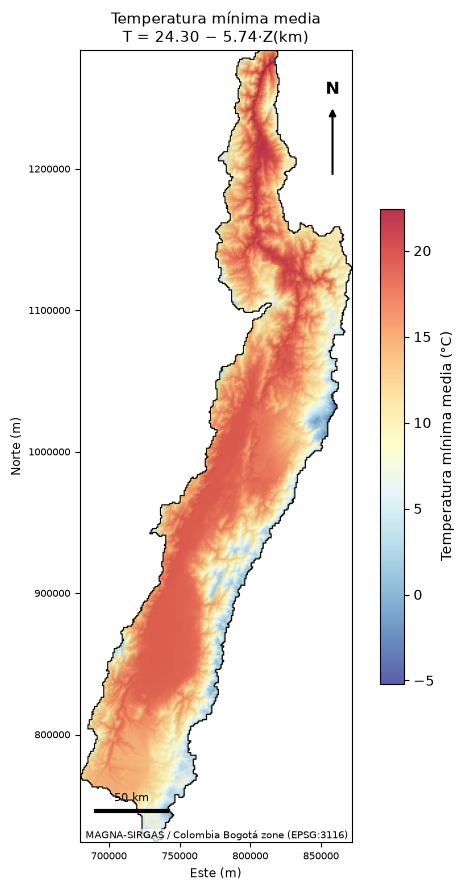

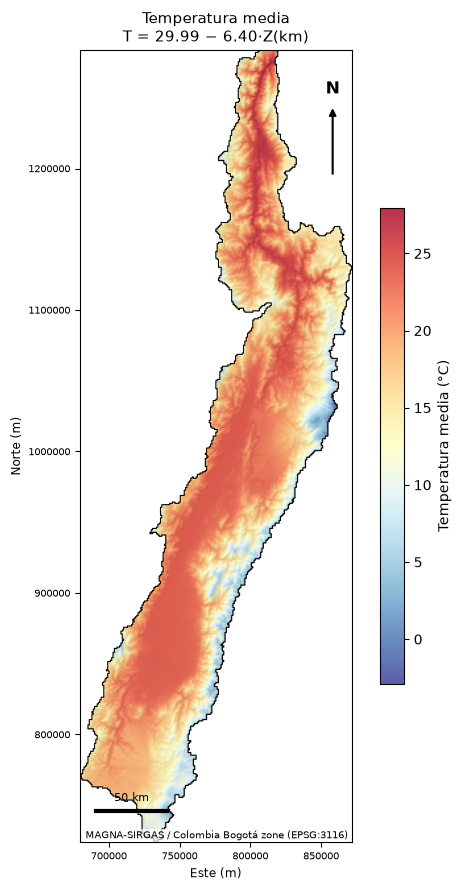

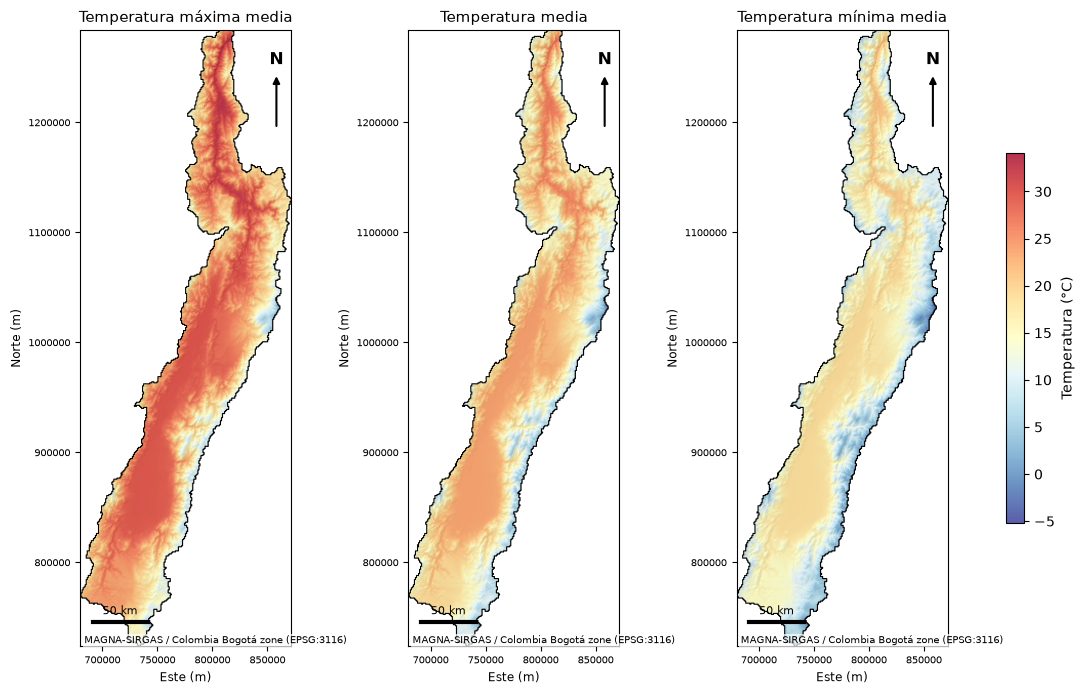

In [5]:
for v, archivo in (("tmax", "fig_mapa_Tmax.png"), ("tmin", "fig_mapa_Tmin.png"), ("tmed", "fig_mapa_Tmed.png")):
    fig, ax = plt.subplots(figsize=(6, 9))
    ax.imshow(sombra, extent=ext, cmap="gray")
    im = ax.imshow(mapas[v], extent=ext, cmap="RdYlBu_r", alpha=0.8)
    plt.colorbar(im, ax=ax, shrink=0.6, label=f"{NOMBRES[v]} (°C)")
    p = PAR[v]
    decorar(ax, f"{NOMBRES[v]}\nT = {p['T0']:.2f} − {p['alpha_C_por_m']*1000:.2f}·Z(km)")
    fig.tight_layout(); fig.savefig(archivo, dpi=200)
    plt.show()

vmin = min(m.min() for m in mapas.values()); vmax = max(m.max() for m in mapas.values())
fig, axs = plt.subplots(1, 3, figsize=(15, 8))
for ax, v in zip(axs, ("tmax", "tmed", "tmin")):
    ax.imshow(sombra, extent=ext, cmap="gray")
    im = ax.imshow(mapas[v], extent=ext, cmap="RdYlBu_r", vmin=vmin, vmax=vmax, alpha=0.8)
    decorar(ax, NOMBRES[v])
fig.colorbar(im, ax=axs, shrink=0.6, label="Temperatura (°C)")
fig.savefig("fig_mapas_T_misma_escala.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Efecto de la elevación: temperatura por franjas de altura
Como la temperatura es una función lineal de Z, su mapa es una "copia" del DEM con otra escala. Esta tabla
cuantifica cuánta área de la cuenca hay en cada franja de elevación y qué temperatura tiene.

In [6]:
franjas = [0, 500, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 6000]
zc = Z.compressed()
filas = []
for z1, z2 in zip(franjas[:-1], franjas[1:]):
    m = (zc >= z1) & (zc < z2)
    if m.sum() == 0:
        continue
    filas.append({"franja (m)": f"{z1}–{z2}" if z2 < 6000 else f"> {z1}",
                  "área (km²)": m.sum() * celda_km2, "área (%)": 100 * m.mean(),
                  **{f"{NOMBRES[v].split()[1].capitalize()} media (°C)": mapas[v].compressed()[m].mean()
                     for v in ("tmax", "tmed", "tmin")}})
tabla_franjas = pd.DataFrame(filas)
display(tabla_franjas.round(1))

amp = (mapas["tmax"] - mapas["tmin"])
print(f"Amplitud térmica diaria (Tmax − Tmin): {amp.max():.1f} °C en las partes bajas → {amp.min():.1f} °C en las más altas")
print(f"Por cada 1.000 m de ascenso, Tmed baja {PAR['tmed']['alpha_C_por_m']*1000:.1f} °C")

,franja (m),área (km²),área (%),Máxima media (°C),Media media (°C),Mínima media (°C)
0,0–500,89.4,0.3,33.1,27.0,21.7
1,500–1000,5779.6,16.4,29.9,24.2,19.1
2,1000–1500,9298.1,26.4,27.6,22.2,17.3
3,1500–2000,8025.1,22.7,24.0,18.9,14.3
4,2000–2500,5441.0,15.4,20.4,15.7,11.5
5,2500–3000,3308.4,9.4,16.9,12.6,8.7
6,3000–3500,1939.9,5.5,13.3,9.3,5.8
7,3500–4000,1188.7,3.4,10.0,6.3,3.1
8,> 4000,212.7,0.6,6.1,2.8,-0.1


Amplitud térmica diaria (Tmax − Tmin): 11.6 °C en las partes bajas → 4.9 °C en las más altas
Por cada 1.000 m de ascenso, Tmed baja 6.4 °C


## 6. Pisos térmicos: sectores más fríos y más cálidos
La Tmed se clasifica según los pisos térmicos usados en Colombia (clasificación de Caldas):

| Piso térmico | Tmed (°C) | Elevación aproximada |
|---|---|---|
| Cálido | > 24 | < 1.000 m |
| Templado | 18 – 24 | 1.000 – 2.000 m |
| Frío | 12 – 18 | 2.000 – 3.000 m |
| Páramo | 6 – 12 | 3.000 – 4.000 m |
| Nival / glacial | < 6 | > 4.000 m |

Los límites de elevación de su cuenca salen de su propia regresión (tabla de abajo).

,piso térmico,Tmed (°C),elevación según la recta (m),área (km²),área (%)
0,Nival / glacial,< 6,"> 3,751",626.9,1.8
1,Páramo,6 – 12,"2,813 – 3,751",3746.0,10.6
2,Frío,12 – 18,"1,874 – 2,813",9312.0,26.4
3,Templado,18 – 24,"936 – 1,874",18864.5,53.5
4,Cálido,> 24,< 936,2733.5,7.7


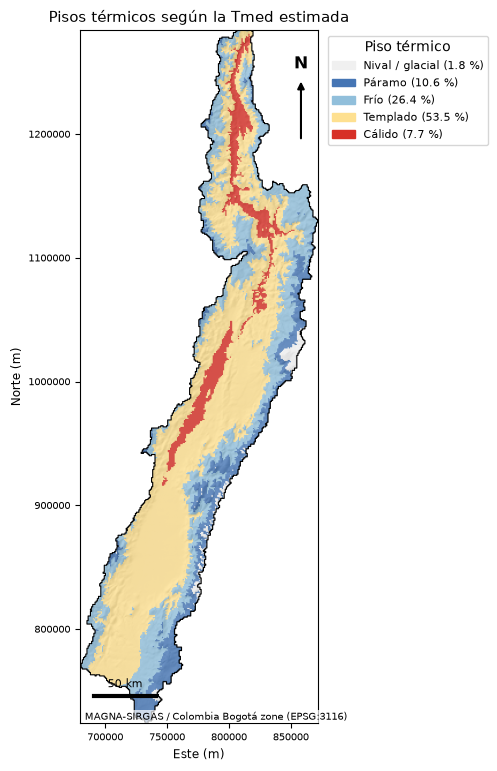

In [7]:
limites = [-50, 6, 12, 18, 24, 50]
pisos = ["Nival / glacial", "Páramo", "Frío", "Templado", "Cálido"]
colores = ["#f0f0f0", "#4575b4", "#91bfdb", "#fee090", "#d73027"]
clase = np.ma.masked_array(np.digitize(mapas["tmed"].filled(np.nan), limites[1:-1]), mask=np.ma.getmaskarray(Z))

a_med, t0_med = PAR["tmed"]["alpha_C_por_m"], PAR["tmed"]["T0"]
filas = []
for i, nombre in enumerate(pisos):
    n = int((clase == i).sum())
    t_sup, t_inf = limites[i + 1], limites[i]
    filas.append({"piso térmico": nombre, "Tmed (°C)": f"{max(t_inf, -50)} – {t_sup}" if i not in (0, 4) else
                  (f"< {t_sup}" if i == 0 else f"> {t_inf}"),
                  "elevación según la recta (m)": f"{max(0, (t0_med - t_sup) / a_med):,.0f} – {(t0_med - t_inf) / a_med:,.0f}"
                  if i not in (0, 4) else (f"> {(t0_med - t_sup) / a_med:,.0f}" if i == 0 else f"< {(t0_med - t_inf) / a_med:,.0f}"),
                  "área (km²)": n * celda_km2, "área (%)": 100 * n / Z.count()})
tabla_pisos = pd.DataFrame(filas)
display(tabla_pisos.round(1))

with rasterio.open("pisos_termicos.tif", "w", **{**perfil, "dtype": "int16", "nodata": -1}) as dst:
    dst.write(clase.filled(-1).astype("int16"), 1)

fig, ax = plt.subplots(figsize=(6, 9))
ax.imshow(sombra, extent=ext, cmap="gray")
ax.imshow(clase, extent=ext, cmap=ListedColormap(colores), norm=BoundaryNorm(np.arange(-0.5, 5), 5), alpha=0.8)
ax.legend(handles=[Patch(color=c, label=f"{p} ({a:.1f} %)") for c, p, a in zip(colores, pisos, tabla_pisos["área (%)"])],
          loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, title="Piso térmico")
decorar(ax, "Pisos térmicos según la Tmed estimada")
fig.savefig("fig_pisos_termicos.png", dpi=200, bbox_inches="tight")
plt.show()

### ¿Dónde están los sectores más fríos y más cálidos?
Para describir los sectores por regiones, la cuenca se divide en franjas de 1° de latitud, de sur a norte:
Macizo Colombiano y alto Cauca → valle geográfico del Cauca → Eje Cafetero → Cauca medio antioqueño → cañón cerca de
Hidroituango. También se listan las coordenadas de las celdas extremas, para ubicarlas en QGIS. Los nevados y
páramos de la cordillera Central suelen ser los sectores más fríos.

In [8]:
filas_i, cols_i = np.nonzero(~np.ma.getmaskarray(Z))
xs = T.c + (cols_i + 0.5) * T.a
ys = T.f + (filas_i + 0.5) * T.e
lon_lat = gpd.GeoSeries(gpd.points_from_xy(xs, ys), crs=CRS).to_crs("EPSG:4326")
lat = lon_lat.y.to_numpy(); lon = lon_lat.x.to_numpy()
tmed_v = mapas["tmed"].compressed(); z_v = Z.compressed()

banda = np.floor(lat).astype(int)
por_lat = (pd.DataFrame({"latitud": banda, "Z": z_v, "Tmed": tmed_v})
           .groupby("latitud").agg(area_km2=("Z", lambda s: len(s) * celda_km2), Z_media_m=("Z", "mean"),
                                    Tmed_media=("Tmed", "mean"), Tmed_min=("Tmed", "min"), Tmed_max=("Tmed", "max")))
por_lat.index = [f"{b}° – {b + 1}° N" for b in por_lat.index]
print("Temperatura media por franjas de latitud (de sur a norte):")
display(por_lat.round(1))

orden = np.argsort(tmed_v)
extremos = pd.concat([
    pd.DataFrame({"sector": "más frío", "lat": lat[orden[:5]], "lon": lon[orden[:5]], "Z_m": z_v[orden[:5]], "Tmed": tmed_v[orden[:5]]}),
    pd.DataFrame({"sector": "más cálido", "lat": lat[orden[-5:]], "lon": lon[orden[-5:]], "Z_m": z_v[orden[-5:]], "Tmed": tmed_v[orden[-5:]]}),
])
print("Celdas extremas (ubíquelas en QGIS con las coordenadas):")
display(extremos.round(3))

Temperatura media por franjas de latitud (de sur a norte):


,area_km2,Z_media_m,Tmed_media,Tmed_min,Tmed_max
2° – 3° N,5515.7,2195.6,15.9,1.0,23.4
3° – 4° N,7830.6,1743.9,18.8,3.5,24.1
4° – 5° N,8815.3,1671.6,19.3,-2.9,24.3
5° – 6° N,8556.6,1795.4,18.5,6.0,26.4
6° – 7° N,4157.6,1638.0,19.5,6.9,27.5
7° – 8° N,407.2,1593.3,19.8,8.6,27.9


Celdas extremas (ubíquelas en QGIS con las coordenadas):


,sector,lat,lon,Z_m,Tmed
0,más frío,4.891,-75.332,5141.0,-2.890
1,más frío,4.883,-75.332,5044.0,-2.270
2,más frío,4.874,-75.332,4993.0,-1.944
3,más frío,4.891,-75.340,4981.0,-1.867
4,más frío,4.900,-75.340,4859.0,-1.087
0,más cálido,7.021,-75.792,375.0,27.590
1,más cálido,7.080,-75.733,372.0,27.609
2,más cálido,7.063,-75.767,371.0,27.615
3,más cálido,7.055,-75.775,365.0,27.654
4,más cálido,7.080,-75.741,322.0,27.929


## 7. Coherencia espacial de los resultados
Se verifica:
1. **Consistencia física:** que Tmax > Tmed > Tmin en todas las celdas, y cuánto difiere la Tmed de la regresión
   de (Tmax + Tmin)/2, que es la que se usará en el punto 6.
2. **Comparación con las estaciones:** se extrae el valor del mapa en la celda de cada estación y se compara con
   la temperatura observada. Parte de la diferencia viene de que la celda de ~930 m tiene una elevación promedio
   distinta de la elevación puntual de la estación; por eso también se compara la elevación del DEM con la de la estación.
3. **Extrapolación:** qué porcentaje de la cuenca está por encima de la estación más alta o por debajo de la más baja.

1) Consistencia física
   Celdas con Tmax ≤ Tmin: 0
   Celdas con Tmed fuera de [Tmin, Tmax]: 0
   Tmed(regresión) − (Tmax+Tmin)/2: entre -0.32 y -0.17 °C (media -0.27 °C)

2) Comparación mapa vs. estaciones dentro de la cuenca (n = 52)


,sesgo (°C),RMSE (°C),error máx. abs. (°C)
Temperatura máxima media,-0.22,2.63,14.63
Temperatura mínima media,-0.03,2.38,13.76
Temperatura media,-0.14,2.32,13.49


   Elevación del DEM − elevación de la estación: media +7 m, RMSE 361 m
   Eso equivale a 2.31 °C de Tmed solo por la resolución del DEM


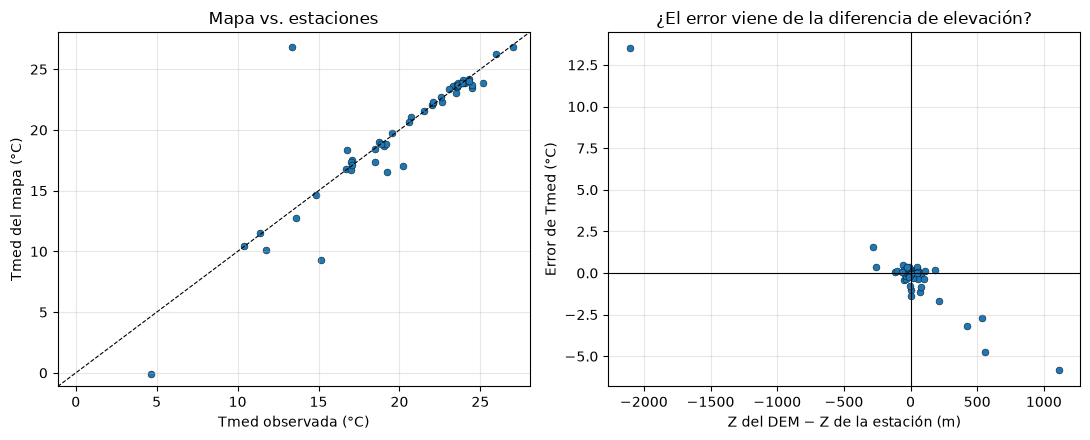

3) Extrapolación
   Estaciones entre 500 y 4150 m
   Área de la cuenca por encima de la estación más alta: 0.4 %
   Área de la cuenca por debajo de la estación más baja: 0.3 %


In [9]:
print("1) Consistencia física")
print(f"   Celdas con Tmax ≤ Tmin: {int((mapas['tmax'] <= mapas['tmin']).sum())}")
print(f"   Celdas con Tmed fuera de [Tmin, Tmax]: {int(((mapas['tmed'] < mapas['tmin']) | (mapas['tmed'] > mapas['tmax'])).sum())}")
dif = mapas["tmed"] - (mapas["tmax"] + mapas["tmin"]) / 2
print(f"   Tmed(regresión) − (Tmax+Tmin)/2: entre {dif.min():+.2f} y {dif.max():+.2f} °C (media {dif.mean():+.2f} °C)")

st = pd.read_csv(ESTACIONES_T)
g = gpd.GeoSeries(gpd.points_from_xy(st.lon, st.lat), crs="EPSG:4326").to_crs(CRS)
st["x"], st["y"] = g.x.to_numpy(), g.y.to_numpy()
st["col"] = np.floor((st.x - T.c) / T.a).astype(int)
st["fila"] = np.floor((st.y - T.f) / T.e).astype(int)
ok = (st.col >= 0) & (st.col < Z.shape[1]) & (st.fila >= 0) & (st.fila < Z.shape[0])
st = st[ok].copy()
st = st[~np.ma.getmaskarray(Z)[st.fila, st.col]].copy()       # solo estaciones dentro de la cuenca
st["Z_DEM"] = Z.data[st.fila, st.col]
for v in ("tmax", "tmin", "tmed"):
    st[f"{v}_mapa"] = mapas[v].data[st.fila, st.col]
    st[f"{v}_error"] = st[f"{v}_mapa"] - st[v]

print(f"\n2) Comparación mapa vs. estaciones dentro de la cuenca (n = {len(st)})")
comp = pd.DataFrame({NOMBRES[v]: {"sesgo (°C)": st[f"{v}_error"].mean(),
                                  "RMSE (°C)": np.sqrt((st[f"{v}_error"] ** 2).mean()),
                                  "error máx. abs. (°C)": st[f"{v}_error"].abs().max()} for v in ("tmax", "tmin", "tmed")}).T
display(comp.round(2))
dz = st.Z_DEM - st.ELEV
print(f"   Elevación del DEM − elevación de la estación: media {dz.mean():+.0f} m, RMSE {np.sqrt((dz**2).mean()):.0f} m")
print(f"   Eso equivale a {np.sqrt((dz**2).mean()) * PAR['tmed']['alpha_C_por_m']:.2f} °C de Tmed solo por la resolución del DEM")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
lim = [st[["tmed", "tmed_mapa"]].min().min() - 1, st[["tmed", "tmed_mapa"]].max().max() + 1]
axs[0].scatter(st.tmed, st.tmed_mapa, s=25, edgecolor="k", lw=0.3)
axs[0].plot(lim, lim, "k--", lw=0.8)
axs[0].set(xlim=lim, ylim=lim, xlabel="Tmed observada (°C)", ylabel="Tmed del mapa (°C)", title="Mapa vs. estaciones")
axs[0].grid(alpha=0.3)
axs[1].scatter(dz, st.tmed_error, s=25, edgecolor="k", lw=0.3)
axs[1].axhline(0, color="k", lw=0.8); axs[1].axvline(0, color="k", lw=0.8)
axs[1].set(xlabel="Z del DEM − Z de la estación (m)", ylabel="Error de Tmed (°C)",
           title="¿El error viene de la diferencia de elevación?")
axs[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig("fig_coherencia_mapa_estaciones.png", dpi=200)
plt.show()

print("3) Extrapolación")
z_est = pd.read_csv(ESTACIONES_T).ELEV
print(f"   Estaciones entre {z_est.min():.0f} y {z_est.max():.0f} m")
print(f"   Área de la cuenca por encima de la estación más alta: {100 * (z_v > z_est.max()).mean():.1f} %")
print(f"   Área de la cuenca por debajo de la estación más baja: {100 * (z_v < z_est.min()).mean():.1f} %")

## 8. Guía para el análisis del informe (ajústela a sus números)
- **Efecto de la elevación:** como α es constante, la temperatura disminuye linealmente con la altura, y el mapa
  reproduce el relieve. Con α ≈ 6,5 °C/km, entre el fondo del cañón y las cumbres de la cordillera Central hay más
  de 25 °C de diferencia en Tmed. La amplitud térmica diaria (Tmax − Tmin) también disminuye con la altura.
- **Sectores más cálidos:** el fondo del cañón del Cauca en el norte, hacia Hidroituango, y el valle geográfico del
  Cauca (unos 900–1.000 m), que ocupan el piso térmico cálido y la parte baja del templado.
- **Sectores más fríos:** las cumbres de la cordillera Central (zona de los nevados del Ruiz, Santa Isabel y Tolima,
  páramos del Quindío) y del Macizo Colombiano y el Puracé en el sur, en los pisos de páramo y nival.
- **Coherencia espacial:** los campos son continuos y físicamente consistentes (Tmax > Tmed > Tmin). Reproducen las
  estaciones con un error del orden del RMSE de la regresión. Hay tres limitaciones:
  - el método no representa efectos locales, como el valle seco más cálido, la exposición de las laderas o las
    inversiones térmicas;
  - las celdas de ~930 m suavizan las cumbres y los fondos de valle;
  - por encima de la estación más alta, la temperatura es una extrapolación de la recta.